# 03 · Default Model

Predicts `target_default` with a **logistic-regression baseline** and **XGBoost**, using engineered bureau and repayment features. Reports **AUC, KS, Gini**, coefficients and **SHAP**, and closes with a monitoring plan.

All model code lives in `src/model.py`, and `uv run python main.py` trains the same models the dashboard uses.

**Design choices**
- **Split by customer** (70/30): a customer's loans never sit in both train and test, which stops leakage through shared bureau features.
- **Collections (`coll_*`) are excluded.** Collections start after delinquency, so they would leak the target.
- Missing-value flags from ingestion are included as features.

In [1]:
import sys
from pathlib import Path

# walk up to the project root (where pyproject.toml lives)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd
from src.config import RAW_DIR
from src.ingestion import build_dataset
import numpy as np
from src import model as M
OUT = ROOT / 'src' / 'analytics' / 'outputs'
OUT.mkdir(parents=True, exist_ok=True)
pd.set_option('display.float_format', '{:,.3f}'.format)
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.spines.top': False, 'axes.spines.right': False})

df, _ = build_dataset(RAW_DIR)
print(f'{len(df):,} loan accounts | default rate {df.target_default.mean():.2%}')

14,685 loan accounts | default rate 16.10%


In [2]:
print(len(M.NUMERIC_FEATURES), 'numeric +', len(M.CATEGORICAL_FEATURES), 'categorical features')
pd.Series(M.FEATURES, name='feature').to_frame().T

37 numeric + 9 categorical features


,0,1,2,3,4,5,6,7,8,9,...,36,37,38,39,40,41,42,43,44,45
feature,age,annual_income,years_employed,num_dependents,years_at_residence,years_employed_missing,num_dependents_missing,years_at_residence_missing,loan_amount,interest_rate_pct,...,rep_pay_ratio,employment_type,loan_type,region,city_tier,housing_type,marital_status,education_level,disbursal_channel,loan_purpose


## 1. Train both models

In [3]:
out = M.train_models(df)
res = out['results']
X_test, y_test = out['X_test'], out['y_test']
metrics = pd.DataFrame({(n, s): r[s] for n, r in res.items() for s in ['train', 'test']}).T
metrics.to_csv(OUT / 'model_metrics.csv')
metrics

AUC  Gini    KS
Logistic Regression train 0.693 0.387 0.296
                    test  0.677 0.353 0.269
XGBoost             train 0.724 0.448 0.341
                    test  0.671 0.343 0.271

## 2. 5-fold customer-grouped cross-validation
A single split can be lucky, so this checks the AUC is stable.

In [4]:
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score
cv = StratifiedGroupKFold(5, shuffle=True, random_state=42)
X, y, groups = df[M.FEATURES], df[M.TARGET], df['customer_id']
cv_auc = {name: cross_val_score(est, X, y, groups=groups, cv=cv, scoring='roc_auc')
          for name, est in [('Logistic Regression', M.build_logreg()), ('XGBoost', M.build_xgb())]}
pd.DataFrame(cv_auc).agg(['mean', 'std']).T

,mean,std
Logistic Regression,0.679,0.009
XGBoost,0.678,0.008


## 3. ROC and KS curves

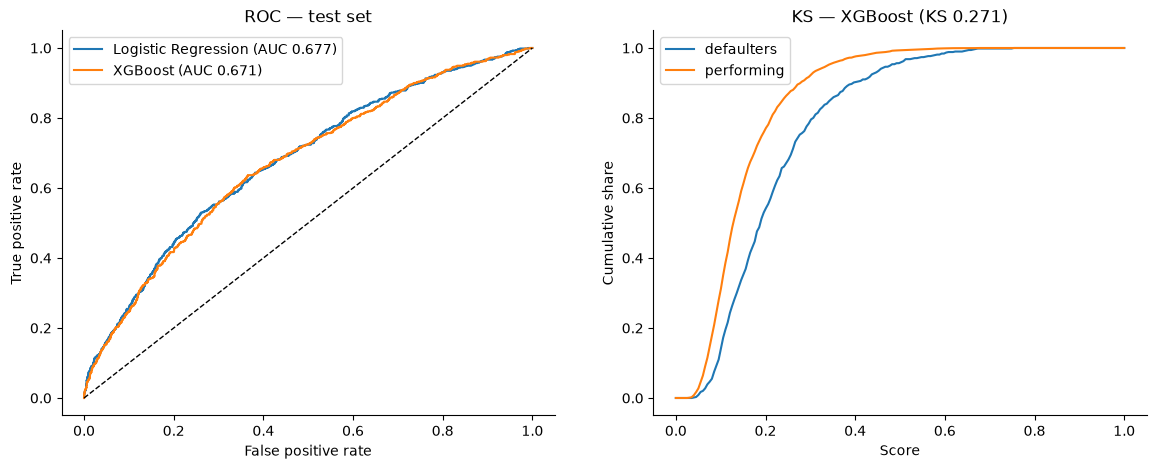

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, r in res.items():
    roc = M.roc_points(y_test, r['test_scores'])
    axes[0].plot(roc.fpr, roc.tpr, label=f"{name} (AUC {r['test']['AUC']:.3f})")
axes[0].plot([0, 1], [0, 1], 'k--', lw=1)
axes[0].set(xlabel='False positive rate', ylabel='True positive rate', title='ROC — test set'); axes[0].legend()

s = res['XGBoost']['test_scores']
grid = np.linspace(0, 1, 200)
cdf_bad = [(s[y_test == 1] <= t).mean() for t in grid]
cdf_good = [(s[y_test == 0] <= t).mean() for t in grid]
axes[1].plot(grid, cdf_bad, label='defaulters'); axes[1].plot(grid, cdf_good, label='performing')
axes[1].set(xlabel='Score', ylabel='Cumulative share', title=f"KS — XGBoost (KS {res['XGBoost']['test']['KS']:.3f})"); axes[1].legend()
plt.show()

## 4. Score decile table (rank-ordering)
The default rate should rise steadily from the lowest to the highest score decile.

In [6]:
dec = pd.DataFrame({'score': res['XGBoost']['test_scores'], 'default': y_test.values})
dec['decile'] = pd.qcut(dec.score.rank(method='first'), 10, labels=range(1, 11))
dec_tbl = dec.groupby('decile', observed=True).agg(accounts=('default', 'size'), default_rate=('default', 'mean'), avg_score=('score', 'mean'))
dec_tbl['capture_rate'] = dec.groupby('decile', observed=True)['default'].sum()[::-1].cumsum()[::-1] / dec['default'].sum()
dec_tbl

,accounts,default_rate,avg_score,capture_rate
decile,,,,
1,441,0.061,0.057,1.000
2,441,0.070,0.079,0.961
3,441,0.109,0.095,0.916
4,441,0.116,0.110,0.847
5,441,0.113,0.126,0.773
6,440,0.123,0.146,0.700
7,441,0.186,0.171,0.622
8,441,0.197,0.207,0.504
9,441,0.259,0.259,0.378


## 5. Logistic regression: coefficients
Odds ratio > 1 increases default risk (numeric features are standardised, so this is the effect per 1 standard deviation).

In [7]:
coef = M.logreg_coefficients(res['Logistic Regression']['model'])
coef.to_csv(OUT / 'logreg_coefficients.csv', index=False)
coef.head(15)

,feature,coefficient,odds_ratio
1,annual_income,-0.210,0.811
29,rep_late_cnt,0.201,1.223
2,years_employed,-0.192,0.826
0,age,-0.176,0.839
41,employment_type_Unemployed,0.141,1.152
25,bureau_mean_dpd,0.127,1.135
19,bureau_active_cnt,-0.116,0.890
8,loan_amount,0.102,1.108
13,loan_to_income,0.100,1.105
64,education_level_Doctorate,0.099,1.104


## 6. XGBoost: SHAP feature importance

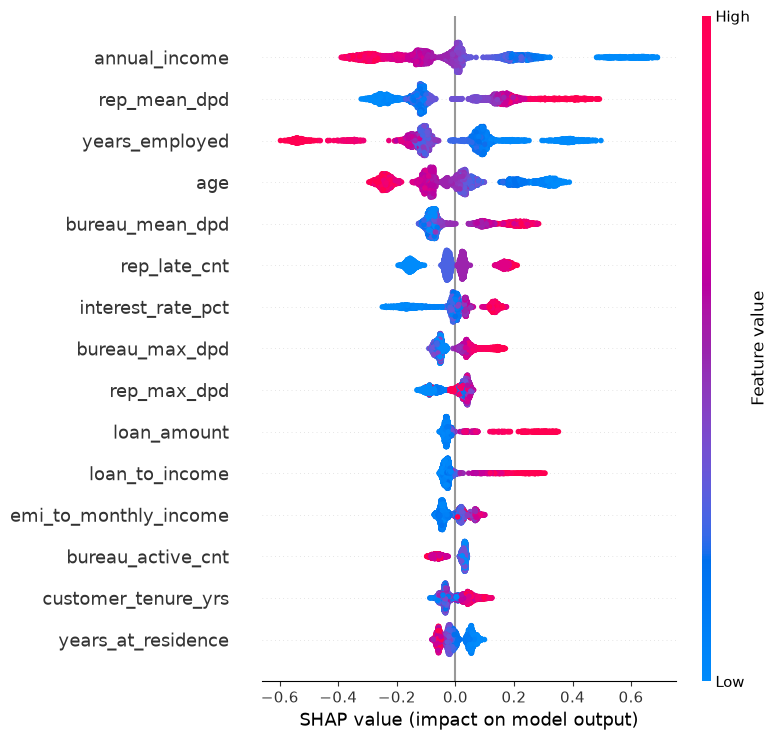

,mean_abs_shap
annual_income,0.174
rep_mean_dpd,0.173
years_employed,0.163
age,0.139
bureau_mean_dpd,0.106
rep_late_cnt,0.081
interest_rate_pct,0.063
bureau_max_dpd,0.057
rep_max_dpd,0.046
loan_amount,0.045


In [8]:
import shap
xgb = res['XGBoost']['model']
sv, Xt = M.shap_values(xgb, X_test)
imp = pd.Series(np.abs(sv).mean(0), index=Xt.columns, name='mean_abs_shap').sort_values(ascending=False)
imp.to_csv(OUT / 'shap_importance.csv')
shap.summary_plot(sv, Xt, max_display=15, show=False)
plt.tight_layout(); plt.show()
imp.head(15).to_frame()

### Account-level drivers (what the dashboard shows per account)

In [9]:
drivers = M.top_drivers(xgb, X_test.head(3), n=5)
for acc, d in zip(df.loc[X_test.head(3).index, 'account_id'], drivers):
    print(acc, '->', ', '.join(f'{f} ({v:+.2f})' for f, v in d))

ACC200001 -> loan_amount (+0.35), loan_to_income (+0.27), rep_late_cnt (+0.17), interest_rate_pct (-0.15), rep_mean_dpd (-0.14)
ACC200004 -> years_employed (+0.42), age (-0.29), rep_mean_dpd (-0.23), annual_income (+0.22), bureau_mean_dpd (+0.22)
ACC200005 -> years_employed (+0.40), age (-0.28), annual_income (+0.23), bureau_mean_dpd (+0.21), rep_mean_dpd (-0.14)


## 7. Results and model choice

Both models reach **test AUC ≈ 0.67 (Gini ≈ 0.33–0.35, KS ≈ 0.26–0.27)**, and customer-grouped CV confirms it (≈ 0.677 for both). The signal in this data is mostly monotonic and additive (income, missed payments, bureau write-offs, loan-to-income), so deeper XGBoost trees just overfit (train AUC 0.87 vs test 0.65 at depth 4). The final XGBoost is shallow (depth 2) and heavily regularised.

- **Logistic regression** is the preferred *production* scorecard: same discrimination, fully explainable coefficients, and easy for model-risk teams to validate.
- **XGBoost + SHAP** drives the dashboard's per-account drivers and acts as a challenger model: if it starts to pull ahead on new data, non-linear effects have appeared.

An AUC near 0.68 is realistic for an application-plus-early-behaviour model on synthetic data designed to have *"clear but not trivial"* signal.

## 8. Monitoring after deployment

| What | How | Trigger |
|---|---|---|
| **Discrimination** | Monthly AUC / Gini / KS on accounts whose outcome window has matured | Gini drops > 5 pts vs development |
| **Population stability** | PSI on the score and on each top-10 feature | PSI > 0.10 investigate, > 0.25 redevelop |
| **Calibration** | Predicted vs actual default rate by score decile and risk band | Any band off by > 20% relative |
| **Data quality** | Missing-rate and range checks on inputs (e.g. bureau DPD missing rate) | Beyond 2× development rate |
| **Segment fairness / drift** | Default rate and score by region, age band, employment type | Unexplained gaps opening |
| **Overrides** | Rate at which analysts override the model's band, and the outcomes | Override rate > 10% or overrides outperforming |

Champion/challenger: logistic regression is the champion and XGBoost the challenger. Both are re-scored monthly, with a formal revalidation every year.